# SmartHire: Job Recommender

In [2]:
# --- Setup: run this first ---
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # make src/ importable

%load_ext autoreload
%autoreload 2

import pandas as pd
from src import config

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from src.features.text_features import build_tfidf

resumes = pd.read_csv(config.RESUMES_CLEAN)
X, y = resumes["Resume"], resumes["Category"]
print(len(X), "resumes |", y.nunique(), "classes")

166 resumes | 25 classes


In [4]:
from src.models.recommender import JobRecommender
from src.models.classifier import load_classifier, predict_top_k

jobs = pd.read_csv(config.JOBS_CLEAN)
resumes = pd.read_csv(config.RESUMES_CLEAN)

clf = load_classifier()
rec = JobRecommender().fit(jobs, resumes)
print("Job matrix:", rec.job_matrix.shape)

Job matrix: (21344, 50000)


In [5]:
pd.set_option("display.max_colwidth", 60)

for cat in ["Data Science", "HR", "Civil Engineer"]:
    text = resumes.loc[resumes["Category"] == cat, "Resume"].iloc[0]
    predicted = predict_top_k(clf, text)[0][0]
    print(f"\n===== {cat} resume  (classifier says: {predicted}) =====")
    display(rec.recommend(text, category=predicted, top_n=5)[["jobtitle", "company", "match_score", "matched_skills"]])


===== Data Science resume  (classifier says: Data Science) =====


,jobtitle,company,match_score,matched_skills
0,Data Scientist Machine Learning,Brillio Technologies Pvt. Ltd,0.494,"[java, machine learning, nlp, numpy, python, scikit-learn]"
1,Data Scientist (bangalore),Aether Infotech Pvt. Ltd.,0.452,"[deep learning, java, machine learning, nlp]"
2,Data Scientist - Machine Learning/nlp,VidPro Consultancy Services,0.450,"[machine learning, nlp, python, sql]"
3,Developer Engineer and Data Scientist,Pin Click - Startup,0.448,"[java, javascript, machine learning, node.js, python]"
4,Sr Data Scietist,Karvy Analytics Limited,0.448,"[machine learning, python, sql, tableau]"



===== HR resume  (classifier says: HR) =====


,jobtitle,company,match_score,matched_skills
0,G.M - Sales - Tamil Nadu,Resource Centric hiring for Client of M/S Resource Centric,0.502,[]
1,HR,B12 Consulting ( India ) Private Limited,0.494,[]
2,Senior NABH Consultant for Chennai & Tamil Nadu,ACME Consulting,0.451,[]
3,HR....,Shriram Institute for Industrial Research,0.422,[]
4,Human Resource Manager,Avenues Consultancy Services hiring for Leading five sta...,0.420,[]



===== Civil Engineer resume  (classifier says: Civil Engineer) =====


,jobtitle,company,match_score,matched_skills
0,Civil Engineer,Vermas consultant services,0.623,[]
1,Civil Engineer Job,TalentPegs hiring for Talentpegs,0.614,[]
2,Civil Engineer,Shriram Institute for Industrial Research,0.579,[]
3,Senior Civil Engineer / Civil Diploma,Axis Jobs,0.547,[]
4,Civil Site Engineer,Mohammed Constructions,0.546,[]


## Evaluation: Precision@10

In [6]:
from src.evaluate import evaluate_recommender, random_baseline

print("Random baseline      P@10 =", round(random_baseline(jobs, resumes), 3))

scores = {}
for w in [0.0, 0.5, 1.0, 2.0]:
    scores[w] = evaluate_recommender(rec, resumes, k=10, role_weight=w)
    print(f"role_weight = {w}:    P@10 = {scores[w]['precision_at_k'].mean():.3f}")

Random baseline      P@10 = 0.022
role_weight = 0.0:    P@10 = 0.677
role_weight = 0.5:    P@10 = 0.722
role_weight = 1.0:    P@10 = 0.749
role_weight = 2.0:    P@10 = 0.764


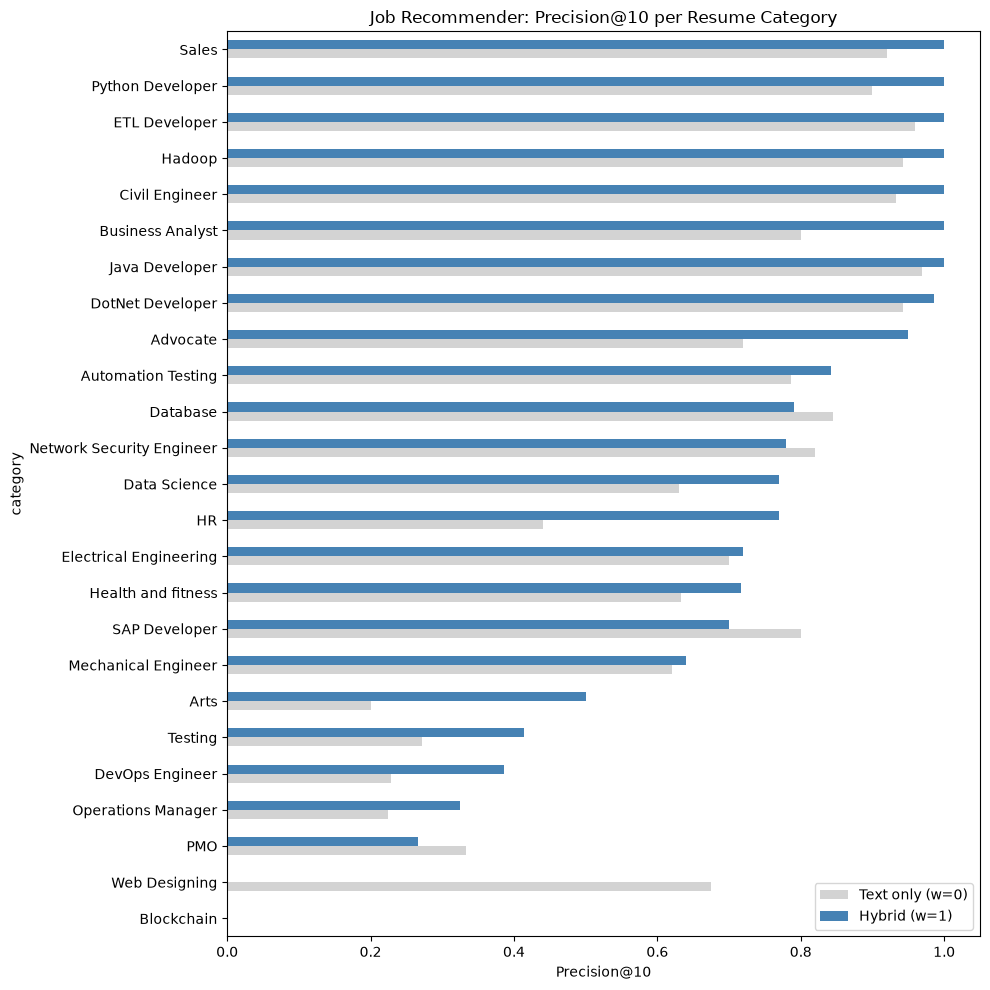

In [7]:
import matplotlib.pyplot as plt

per_cat = pd.DataFrame({
    "Text only (w=0)": scores[0.0].groupby("category")["precision_at_k"].mean(),
    "Hybrid (w=1)":    scores[1.0].groupby("category")["precision_at_k"].mean(),
}).sort_values("Hybrid (w=1)")

ax = per_cat.plot.barh(figsize=(10, 10), color=["lightgray", "steelblue"])
ax.set_xlabel("Precision@10")
ax.set_title("Job Recommender: Precision@10 per Resume Category")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "03_precision_at_k.png", dpi=150)
plt.show()

## Conclusions

1. Template stop words, The HR resume got mixed because of misleading and unwanted wordings 
2. Thanks to hybrid engine, the scrore went from 0.677to 0.749.
3. Because the classifier mislabels web designers as Java Developers, its score came to 0
4. Used role_weight as 1.0 because of personalisation, a higher weight makes all candidates in a category get nearly the same list.

## Skill-Gap Report

In [8]:
from src.models.skill_gap import skill_gap_report

for cat in ["Data Science", "Java Developer", "HR"]:
    text = resumes.loc[resumes["Category"] == cat, "Resume"].iloc[0]
    predicted = predict_top_k(clf, text)[0][0]
    report = skill_gap_report(text, rec, category=predicted)

    print(f"\n===== {cat} resume =====")
    print("Skill coverage :", f"{report['coverage']:.0%}")
    print("Missing skills :", report["missing"])
    display(report["market"])


===== Data Science resume =====
Skill coverage : 48%
Missing skills : ['statistics', 'hadoop', 'c++', 'hive', 'matlab', 'spark', 'communication', 'data analysis', 'nosql', 'agile']


,skill,demand_pct,have
0,machine learning,96,True
1,python,66,True
2,statistics,58,False
3,hadoop,48,False
4,java,32,True
5,sql,30,True
6,c++,26,False
7,nlp,26,True
8,hive,24,False
9,matlab,22,False



===== Java Developer resume =====
Skill coverage : 36%
Missing skills : ['hibernate', 'sql', 'jquery', 'html', 'communication', 'oracle', 'css', 'mysql']


,skill,demand_pct,have
0,java,94,True
1,hibernate,42,False
2,sql,30,False
3,javascript,26,True
4,jquery,24,False
5,html,20,False
6,communication,18,False
7,oracle,18,False
8,css,16,False
9,mysql,14,False



===== HR resume =====
Skill coverage : 0%
Missing skills : ['recruitment', 'payroll', 'communication', 'compliance']


,skill,demand_pct,have
0,recruitment,50,False
1,payroll,26,False
2,communication,18,False
3,compliance,16,False
4,leadership,8,False
5,sales,4,False
6,employee relations,4,False
7,excel,4,False
8,marketing,4,False
9,php,4,False
